<a href="https://colab.research.google.com/github/Ayan-Rony/LearningML/blob/main/dog_vs_cat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd


In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten,BatchNormalization,Dropout

In [ ]:
#Generators
train_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/drive/MyDrive/dog vs cat (CNN)/cat vs dog(CNN)/train',
    labels='inferred',
    label_mode = 'int',#makes into 0,1
    batch_size=32,
    image_size=(256,256)
)

validation_ds=keras.utils.image_dataset_from_directory(
    directory = '/content/drive/MyDrive/dog vs cat (CNN)/cat vs dog(CNN)/validation',
    labels='inferred',
    label_mode = 'int',#makes into 0,1
    batch_size=32,
    image_size=(256,256)
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [ ]:
# Normalise
def process(image,label):
  image = tf.cast(image/255. ,tf.float32)
  return image,label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)
#making pixel values between 0 to 1 to get efficient output


In [ ]:
# CNN model

model = Sequential()
model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3))) #Convolutional Layer,32- number of filters
model.add(BatchNormalization())#to reduce overfitting
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid')) #Pooling Layer

model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu')) #Convolutional Layer,64-number of filters
model.add(BatchNormalization())#to reduce overfitting
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid')) #Pooling Layer

model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu')) #Convolutional Layer,128-number of filters
model.add(BatchNormalization())#to reduce overfitting
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid')) #Pooling Layer

# model.add(Conv2D(256,kernel_size=(3,3),padding='valid',activation='relu')) #Convolutional Layer,128-number of filters
# #model.add(BatchNormalization())#to reduce overfitting
# model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid')) #Pooling Layer

model.add(Flatten())

# model.add(Dense(256,activation='relu'))
model.add(Dense(128,activation='relu'))
model.add(Dropout(0.1))#to reduce overfitting
model.add(Dense(64,activation='relu'))
model.add(Dropout(0.1))#to reduce overfitting

model.add(Dense(1,activation='sigmoid'))

In [ ]:
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_25 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
#compilation
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])


In [ ]:
history=model.fit(train_ds,epochs=10,validation_data=validation_ds)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 1911s 3s/step - accuracy: 0.5456 - loss: 2.5859 - val_accuracy: 0.5268 - val_loss: 0.6676
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 117s 187ms/step - accuracy: 0.6019 - loss: 0.6453 - val_accuracy: 0.6480 - val_loss: 0.5969
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 135s 216ms/step - accuracy: 0.6636 - loss: 0.5877 - val_accuracy: 0.6294 - val_loss: 0.6263
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 131s 209ms/step - accuracy: 0.7383 - loss: 0.4946 - val_accuracy: 0.7214 - val_loss: 0.5932
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 130s 209ms/step - accuracy: 0.7720 - loss: 0.4335 - val_accuracy: 0.7914 - val_loss: 0.4504
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 110s 176ms/step - accuracy: 0.7908 - loss: 0.3927 - val_accuracy: 0.7606 - val_loss: 0.4801
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 118s 188ms/step - accuracy: 0.8279 - loss: 0.3338 - val_accuracy: 0.8000 - val_loss: 0.4528
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 116s 185ms/step - accuracy: 0.8417 - l

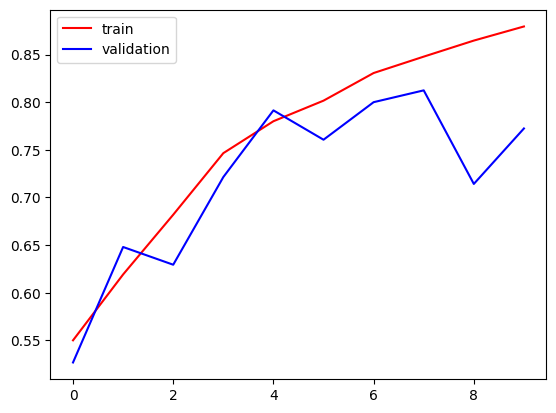

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

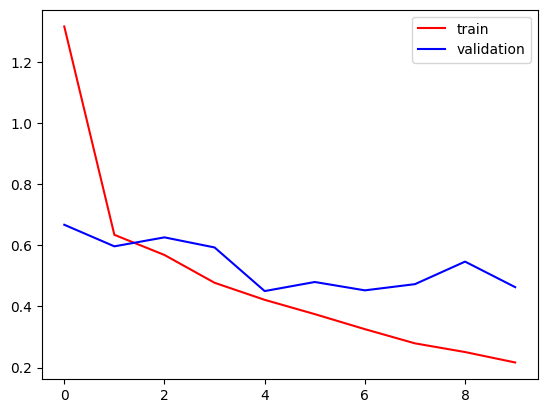

In [ ]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()


In [ ]:
import cv2

In [ ]:
test_img=cv2.imread('/content/drive/MyDrive/dog vs cat (CNN)/cat vs dog(CNN)/test/dogs/dog (10).jpg')

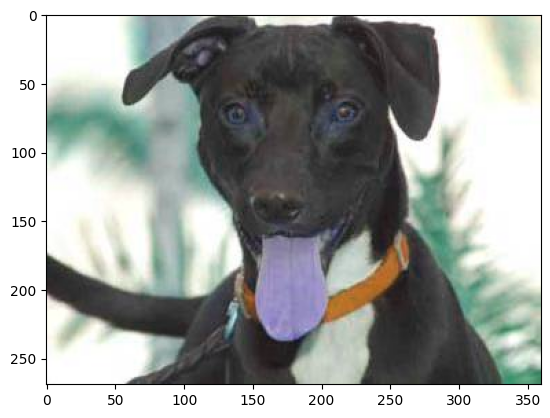

In [ ]:
plt.imshow(test_img)

In [ ]:
test_img.shape


(269, 360, 3)

In [ ]:
test_img=cv2.resize(test_img,(256,256))
#

In [ ]:
test_input=test_img.reshape(1,256,256,3)

In [ ]:
model.predict(test_input)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


array([[1.]], dtype=float32)